# Interpretabilidad (Etapa B)

La consigna de TP3 (Etapa B) pide dos cosas sobre los modelos de la Etapa A:

1. Usar SHAP y/o Feature Importance para identificar qué variables más afectan al error.
2. Analizar si el sesgo detectado antes (notebooks 2 y 4: ciclo diario, bioma, elevación) fue **efectivamente
   capturado y corregido** por el modelo refinado.

Esta notebook carga los **dos modelos reales de Etapa A**, ya entrenados y con validación cruzada temporal en
`7_modelado_global.ipynb` -regresión lineal regularizada (Lasso, elegida como interpretable) y Random Forest
(elegido como mínimo error)-, y corre sobre ellos feature importance, SHAP y la comparación de sesgo pre/post
corrección. Ya no entrena nada: usa `joblib.load()` sobre los pipelines guardados en
`data/processed/modelos/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo

PROCESSED = '../data/processed/'
OUT = '../data/out/interpretabilidad/'
MODELOS_DIR = '../data/processed/modelos/'

aplicar_estilo()
figuras = {}

C:\Users\usuario\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga de features (mismo esquema que `7_modelado_global.ipynb`) + target y variables de sesgo

Los modelos guardados esperan exactamente el mismo set de columnas con el que se entrenaron en
`7_modelado_global.ipynb`, así que esta sección replica esa misma carga: `panel_features_error_temp_c.csv`
(features de `3_analisis_temporal.ipynb` -lags 6/24, rolling, dirección de viento, humedad, vecinas-) mergeado con
columnas de `dataset_modelado.csv` (hora cíclica, geográficas, `bioma`, más `hora_local` para el análisis de sesgo
de la sección 6). Se mergea por `station_id` + `target_hour_utc`.

In [2]:
features = pd.read_csv(PROCESSED + 'panel_features_error_temp_c.csv', parse_dates=['target_hour_utc'])

cols_modelado = ['station_id', 'target_hour_utc', 'error_temp_c', 'abs_error_temp_c', 'target_valido_temp_c',
                  'hora_local', 'hora_sin', 'hora_cos', 'elevation',
                  'dist_agua_km', 'dist_aeropuerto_km', 'dist_area_urbana_km', 'area_urbana_km2',
                  'sobre_agua', 'en_area_urbana', 'bioma', 'fcst_temp_c', 'fcst_pop_pct', 'split']
modelado = pd.read_csv(PROCESSED + 'dataset_modelado.csv', usecols=cols_modelado, parse_dates=['target_hour_utc'])

# features también trae su propia columna error_temp_c (la versión con interpolación acotada de 3_analisis_temporal.ipynb,
# pensada para el diagnóstico de estacionariedad/ACF, no como target): se dropea antes del merge para que no haya
# ambigüedad de nombres -el target real es siempre el de dataset_modelado.csv (el "crudo", fcst - obs).
features = features.drop(columns='error_temp_c')

assert not features.duplicated(['station_id', 'target_hour_utc']).any(), 'panel_features_error_temp_c tiene pares estación+hora repetidos'
assert not modelado.duplicated(['station_id', 'target_hour_utc']).any(), 'dataset_modelado tiene pares estación+hora repetidos'

datos = features.merge(modelado, on=['station_id', 'target_hour_utc'])
datos[['sobre_agua', 'en_area_urbana']] = datos[['sobre_agua', 'en_area_urbana']].astype(int)

print(f'{len(datos):,} filas tras el merge')

165,184 filas tras el merge


## 2. Matriz de features (X) y target (y)

Mismas listas de features que `7_modelado_global.ipynb` (`FEATURES_NUMERICAS`/`FEATURES_BINARIAS`/
`FEATURES_CATEGORICAS`) -tienen que coincidir exactamente con las que se usaron para entrenar, porque cada modelo
guardado incluye su propio preprocesador (`ColumnTransformer`) ya ajustado a esos nombres de columna. Incluye las
variables agregadas en la auditoría de la notebook 7 (`obs_dewpoint_c_lag6`, `obs_windspeed_kmh_lag6` -punto 2- y
`fcst_temp_c`/`fcst_pop_pct`, sumadas antes por la misma razón). Mismo criterio de validez que el resto del
pipeline: `target_valido_temp_c` + sin ningún faltante en las features.

In [3]:
FEATURES_NUMERICAS = [
    'error_temp_c_lag6', 'error_temp_c_lag24', 'error_temp_c_roll3_mean',
    'error_temp_c_vecinas_lag6_mean',
    'obs_wind_direction_sin_lag6', 'obs_wind_direction_cos_lag6',
    'obs_rh_pct_lag6', 'obs_dewpoint_c_lag6', 'obs_windspeed_kmh_lag6',
    'hora_sin', 'hora_cos',
    'elevation', 'dist_agua_km', 'dist_aeropuerto_km', 'dist_area_urbana_km', 'area_urbana_km2',
    'fcst_temp_c', 'fcst_pop_pct',
]
FEATURES_BINARIAS = ['sobre_agua', 'en_area_urbana']
FEATURES_CATEGORICAS = ['bioma']
FEATURES = FEATURES_NUMERICAS + FEATURES_BINARIAS + FEATURES_CATEGORICAS

mascara = datos['target_valido_temp_c'] & datos[FEATURES].notna().all(axis=1)
datos_modelo = datos[mascara].copy().sort_values('target_hour_utc').reset_index(drop=True)

print(f'{len(datos_modelo):,} de {len(datos):,} filas entran al modelo ({100 * mascara.mean():.1f}%)')
print(f'Features: {FEATURES}')

X_test = datos_modelo.loc[datos_modelo['split'] == 'test', FEATURES]
y_test = datos_modelo.loc[datos_modelo['split'] == 'test', 'error_temp_c']

print(f'test: {len(X_test):,} filas')

110,303 de 165,184 filas entran al modelo (66.8%)
Features: ['error_temp_c_lag6', 'error_temp_c_lag24', 'error_temp_c_roll3_mean', 'error_temp_c_vecinas_lag6_mean', 'obs_wind_direction_sin_lag6', 'obs_wind_direction_cos_lag6', 'obs_rh_pct_lag6', 'obs_dewpoint_c_lag6', 'obs_windspeed_kmh_lag6', 'hora_sin', 'hora_cos', 'elevation', 'dist_agua_km', 'dist_aeropuerto_km', 'dist_area_urbana_km', 'area_urbana_km2', 'fcst_temp_c', 'fcst_pop_pct', 'sobre_agua', 'en_area_urbana', 'bioma']
test: 27,353 filas


## 3. Carga de los modelos entrenados en `7_modelado_global.ipynb`

Los dos modelos finales de Etapa A -elegidos ahí por mejor MAE test dentro de cada categoría, con validación
cruzada temporal (`TimeSeriesSplit`)- quedaron guardados como pipelines completos (preprocesamiento + modelo) con
`joblib`. Acá sólo se cargan y se usan para predecir -no se reentrena nada.

In [4]:
modelo_interpretable_final = joblib.load(MODELOS_DIR + 'modelo_interpretable_temp_c.joblib')
modelo_min_error_final = joblib.load(MODELOS_DIR + 'modelo_min_error_temp_c.joblib')

nombre_interpretable = type(modelo_interpretable_final.named_steps['modelo']).__name__
nombre_min_error = type(modelo_min_error_final.named_steps['modelo']).__name__

print(f'Modelo interpretable (entregable 1): {nombre_interpretable}')
print(f'Modelo de mínimo error (entregable 2): {nombre_min_error}')

Modelo interpretable (entregable 1): DecisionTreeRegressor
Modelo de mínimo error (entregable 2): RandomForestRegressor


In [5]:
def mae(y_true, y_pred):
    return np.abs(y_true - y_pred).mean()


resultados = pd.DataFrame({
    'modelo': ['cero (no corregir)', f'interpretable ({nombre_interpretable})', f'mínimo error ({nombre_min_error})'],
    'MAE_test': [
        mae(y_test, 0),
        mae(y_test, modelo_interpretable_final.predict(X_test)),
        mae(y_test, modelo_min_error_final.predict(X_test)),
    ],
})
resultados['mejora_vs_cero_pct'] = 100 * (1 - resultados['MAE_test'] / resultados.loc[0, 'MAE_test'])
resultados.round(3)

,modelo,MAE_test,mejora_vs_cero_pct
0,cero (no corregir),1.240,0.000
1,interpretable (DecisionTreeRegressor),1.135,8.479
2,mínimo error (RandomForestRegressor),1.067,13.978


Estos números deberían coincidir con los que ya se vieron en `7_modelado_global.ipynb` (son los mismos modelos,
sobre el mismo split de test) -sirve como chequeo de que la carga fue correcta. Acá sí es la evaluación real de
Etapa A, no un placeholder.

## 4. Feature Importance (modelo interpretable)

Función genérica: usa `coef_` si el modelo es lineal, o `feature_importances_` si es de árbol/ensamble. Así sirve
para cualquiera de los dos modelos reales, sea cual sea el algoritmo que termine usando cada uno.

In [6]:
def importancia_features(modelo, nombres_features):
    if hasattr(modelo, "coef_"):
        valores = np.abs(modelo.coef_)
        tipo = "coeficiente (valor absoluto)"
    elif hasattr(modelo, "feature_importances_"):
        valores = modelo.feature_importances_
        tipo = "feature_importances_"
    else:
        raise AttributeError("El modelo no tiene coef_ ni feature_importances_: pasar otra técnica de importancia.")
    return pd.Series(valores, index=nombres_features, name=tipo).sort_values(ascending=False)


nombres_features_interpretable = modelo_interpretable_final.named_steps["prep"].get_feature_names_out()
importancia_interpretable = importancia_features(modelo_interpretable_final.named_steps["modelo"], nombres_features_interpretable)
importancia_interpretable


num__error_temp_c_lag24                       0.472458
num__hora_sin                                 0.142977
num__error_temp_c_lag6                        0.133340
num__hora_cos                                 0.086002
num__fcst_pop_pct                             0.077598
num__obs_rh_pct_lag6                          0.033959
num__fcst_temp_c                              0.013732
num__obs_windspeed_kmh_lag6                   0.009410
num__elevation                                0.006553
num__obs_dewpoint_c_lag6                      0.004387
num__dist_agua_km                             0.003609
num__obs_wind_direction_cos_lag6              0.003466
num__error_temp_c_vecinas_lag6_mean           0.003082
num__dist_area_urbana_km                      0.003040
num__error_temp_c_roll3_mean                  0.002537
num__area_urbana_km2                          0.001739
cat__bioma_Northern Forests                   0.000993
num__dist_aeropuerto_km                       0.000946
cat__bioma

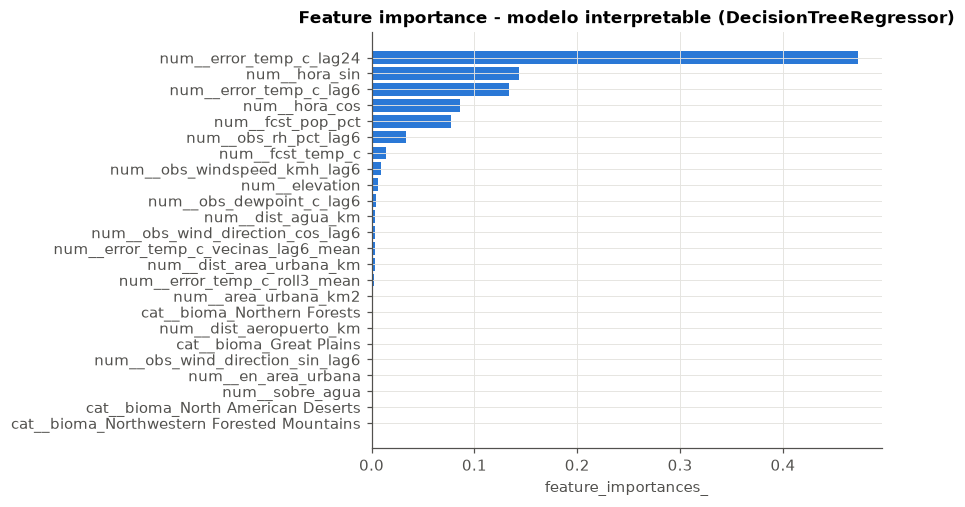

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.barh(importancia_interpretable.index[::-1], importancia_interpretable.values[::-1], color=AZUL)
ax.set(xlabel=importancia_interpretable.name, title=f'Feature importance - modelo interpretable ({nombre_interpretable})')
figuras['01_feature_importance_interpretable'] = fig
plt.show()

## 5. SHAP (modelo de mínimo error)

`TreeExplainer` -exacto y rápido para modelos de árbol/ensamble, que es lo que terminó siendo el modelo de mínimo
error (`Random Forest`). El `TreeExplainer` necesita la matriz ya preprocesada (después del `ColumnTransformer` del
pipeline, con `bioma` ya en one-hot) y el estimador "pelado", no el pipeline completo -por eso se desarma el
pipeline en sus dos pasos acá abajo. Si en una corrida futura el modelo de mínimo error no fuera de árbol/ensamble,
`shap.KernelExplainer` es el fallback genérico (mucho más lento).

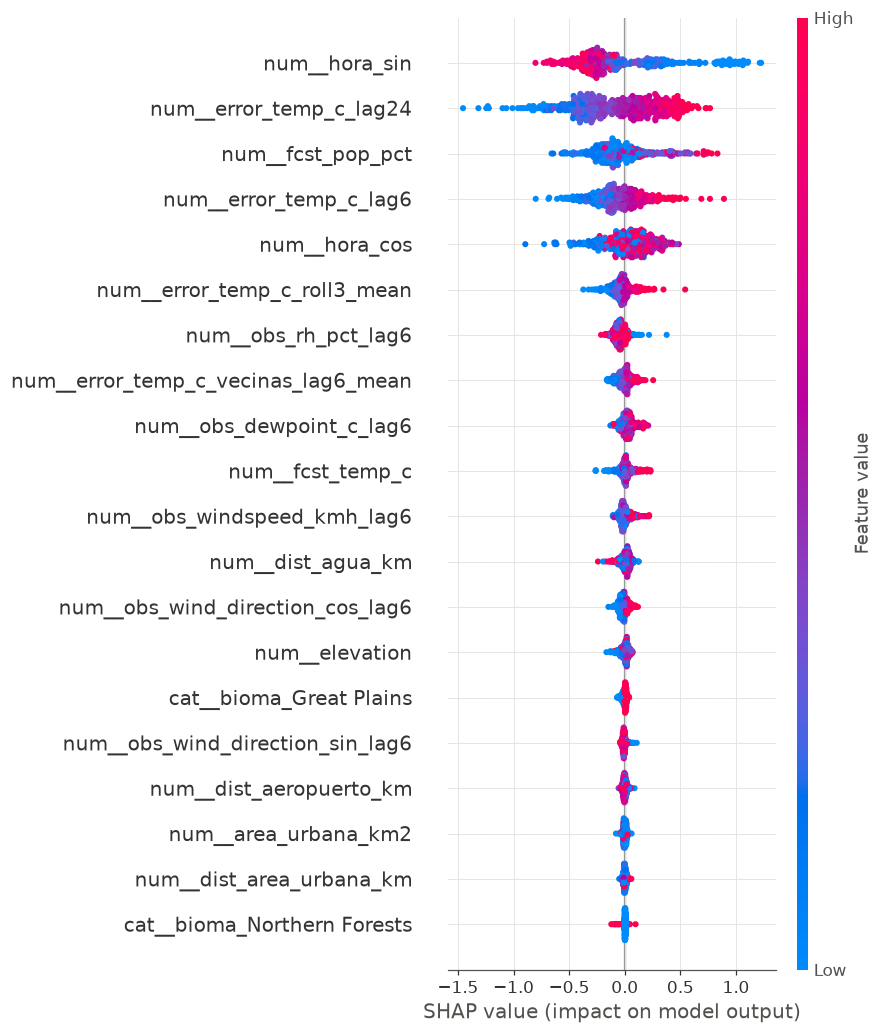

In [8]:
prep_min_error = modelo_min_error_final.named_steps['prep']
estimador_min_error = modelo_min_error_final.named_steps['modelo']
nombres_features_min_error = prep_min_error.get_feature_names_out()

X_test_transformado = prep_min_error.transform(X_test)
if hasattr(X_test_transformado, 'toarray'):  # por si el OneHotEncoder devuelve una matriz sparse
    X_test_transformado = X_test_transformado.toarray()
X_test_transformado = pd.DataFrame(X_test_transformado, columns=nombres_features_min_error, index=X_test.index)

MUESTRA_SHAP = min(500, len(X_test_transformado))  # chico a propósito: con max_depth=32 (HalvingRandomSearchCV), TreeSHAP es mucho más caro por muestra
X_shap = X_test_transformado.sample(MUESTRA_SHAP, random_state=0) if len(X_test_transformado) > MUESTRA_SHAP else X_test_transformado

explainer = shap.TreeExplainer(estimador_min_error)
shap_values = explainer(X_shap)

shap.summary_plot(shap_values, X_shap, show=False)
fig = plt.gcf()
figuras['02_shap_summary_min_error'] = fig
plt.show()

In [9]:
importancia_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=nombres_features_min_error,
                              name='|SHAP| promedio').sort_values(ascending=False)
importancia_shap

num__hora_sin                                 0.341326
num__error_temp_c_lag24                       0.328094
num__fcst_pop_pct                             0.181839
num__error_temp_c_lag6                        0.169410
num__hora_cos                                 0.159574
num__error_temp_c_roll3_mean                  0.063738
num__obs_rh_pct_lag6                          0.053590
num__error_temp_c_vecinas_lag6_mean           0.045633
num__obs_dewpoint_c_lag6                      0.043428
num__fcst_temp_c                              0.042067
num__obs_windspeed_kmh_lag6                   0.033321
num__dist_agua_km                             0.032818
num__obs_wind_direction_cos_lag6              0.028714
num__elevation                                0.024917
cat__bioma_Great Plains                       0.012997
num__obs_wind_direction_sin_lag6              0.012405
num__dist_aeropuerto_km                       0.012098
num__area_urbana_km2                          0.010401
num__dist_

## 6. Permutation Importance (ambos modelos)

`feature_importances_`/`coef_` (sección 4) no son comparables entre familias de modelos distintas -tienen escalas
distintas (un coeficiente estandarizado no es lo mismo que una reducción de impureza), y tampoco corresponden a las
mismas columnas: el árbol ve cada dummy de `bioma` por separado, no la categórica completa. SHAP (sección 5) sí es
comparable en principio, pero sólo se calculó para el modelo de mínimo error (`TreeExplainer` necesita un modelo de
árbol/ensamble; el modelo interpretable sería mucho más lento con `KernelExplainer`).

`sklearn.inspection.permutation_importance` (`Clase_12_Interpretabilidad.ipynb`) resuelve ambos problemas: es
*model-agnostic* (funciona igual para cualquier `Pipeline`, sin importar el estimador final) y se calcula sobre las
columnas **originales** de `X_test` (antes del `ColumnTransformer`), así que `bioma` cuenta como una sola feature
permutada en bloque, no como 5 dummies sueltas. La importancia es, literalmente, cuánto empeora `MAE_test` (en °C,
mismas unidades que el resto de la notebook) al romper la relación entre esa columna y el target barajándola -
promedio de 10 repeticiones por columna, para no depender de una sola barajada con suerte.

In [10]:
from sklearn.inspection import permutation_importance

N_REPEATS_PI = 10

def permutation_importance_series(modelo, nombre_modelo):
    resultado = permutation_importance(modelo, X_test, y_test, scoring='neg_mean_absolute_error',
                                        n_repeats=N_REPEATS_PI, random_state=0, n_jobs=1)
    return pd.Series(resultado.importances_mean, index=FEATURES, name=nombre_modelo).sort_values(ascending=False)


permutation_interpretable = permutation_importance_series(modelo_interpretable_final, f'interpretable ({nombre_interpretable})')
permutation_min_error = permutation_importance_series(modelo_min_error_final, f'mínimo error ({nombre_min_error})')

permutation_interpretable

hora_sin                          0.127198
error_temp_c_lag6                 0.074536
hora_cos                          0.063528
error_temp_c_lag24                0.056278
fcst_pop_pct                      0.017019
obs_rh_pct_lag6                   0.004275
fcst_temp_c                       0.003156
obs_dewpoint_c_lag6               0.002917
error_temp_c_vecinas_lag6_mean    0.001985
dist_agua_km                      0.001963
elevation                         0.001146
obs_wind_direction_cos_lag6       0.000390
area_urbana_km2                   0.000328
dist_area_urbana_km               0.000140
obs_wind_direction_sin_lag6       0.000000
sobre_agua                        0.000000
en_area_urbana                    0.000000
bioma                            -0.000014
obs_windspeed_kmh_lag6           -0.000053
dist_aeropuerto_km               -0.000113
error_temp_c_roll3_mean          -0.000253
Name: interpretable (DecisionTreeRegressor), dtype: float64

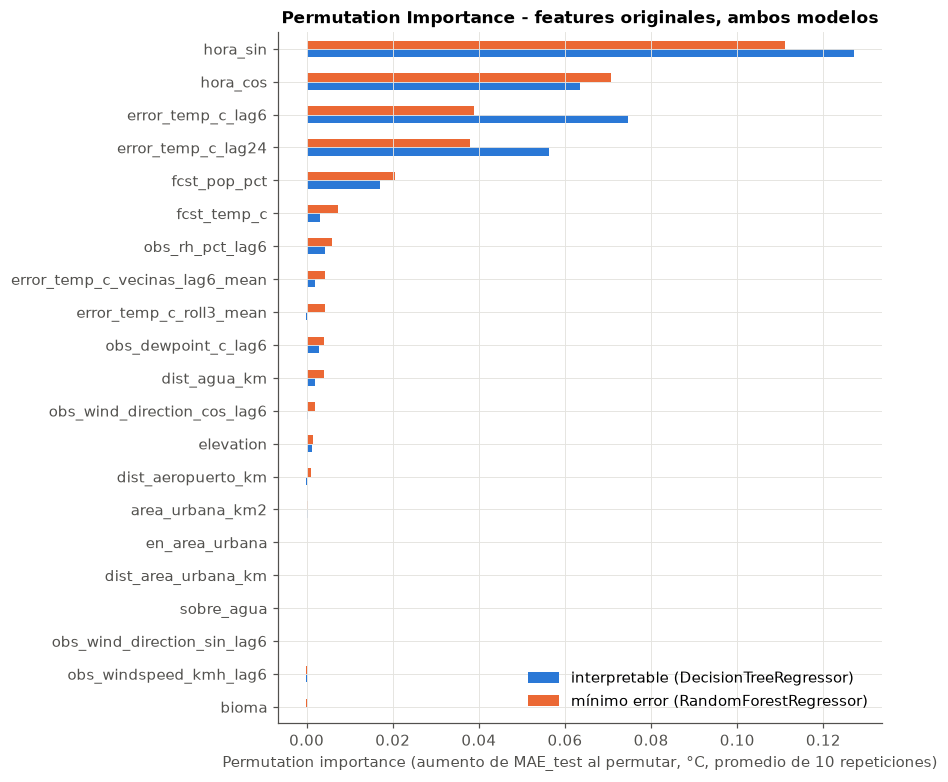

,interpretable (DecisionTreeRegressor),mínimo error (RandomForestRegressor)
hora_sin,0.1272,0.1110
hora_cos,0.0635,0.0707
error_temp_c_lag6,0.0745,0.0388
error_temp_c_lag24,0.0563,0.0380
fcst_pop_pct,0.0170,0.0206
fcst_temp_c,0.0032,0.0073
obs_rh_pct_lag6,0.0043,0.0059
error_temp_c_vecinas_lag6_mean,0.0020,0.0044
error_temp_c_roll3_mean,-0.0003,0.0044
obs_dewpoint_c_lag6,0.0029,0.0041


In [11]:
comparacion_permutacion = pd.DataFrame({
    permutation_interpretable.name: permutation_interpretable,
    permutation_min_error.name: permutation_min_error,
}).sort_values(permutation_min_error.name)

fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
comparacion_permutacion.plot(kind='barh', ax=ax, color=[AZUL, NARANJA])
ax.set(xlabel='Permutation importance (aumento de MAE_test al permutar, °C, promedio de 10 repeticiones)',
       title='Permutation Importance - features originales, ambos modelos')
ax.legend(frameon=False)
figuras['06_permutation_importance_comparacion'] = fig
plt.show()
comparacion_permutacion.round(4).sort_values(permutation_min_error.name, ascending=False)

Las features de baja importancia coinciden entre los tres métodos -`bioma`, `sobre_agua`/`en_area_urbana`,
`obs_windspeed_kmh_lag6`, `dist_aeropuerto_km`/`dist_area_urbana_km` quedan cerca de cero (o levemente negativas,
ruido) tanto en `feature_importances_`/`coef_` (sección 4) y SHAP (sección 5) como acá -confirma que esas
conclusiones son robustas al método, no un artefacto de cómo cada técnica reparte el crédito.

El top difiere más de lo esperable, y es revelador:

- **Modelo interpretable (árbol)**: `feature_importances_` (impureza) tenía a `error_temp_c_lag24` muy por delante
  de todo lo demás (0,47 vs. 0,14 de `hora_sin`). Permutation importance invierte el orden -`hora_sin` (0,127) >
  `error_temp_c_lag6` (0,075) > `hora_cos` (0,064) > `error_temp_c_lag24` recién cuarto (0,056)-. La impureza de un
  árbol tiende a sobrestimar variables continuas que generan muchos cortes posibles; permutation importance, al
  medir el impacto real en `MAE_test`, es la lectura más confiable de las dos.
- **Modelo de mínimo error (Random Forest)**: SHAP tenía a `fcst_pop_pct` como 3ª feature (0,182, por delante de
  `error_temp_c_lag6`); permutation importance la baja al 5º lugar (0,021), detrás de `hora_cos` (0,071) y de los
  dos lags del error. `hora_sin` es la única que se mantiene 1ª en los tres métodos para este modelo.

**Por qué puede diferir, y por qué no invalida nada**: `hora_sin`/`hora_cos` están correlacionadas entre sí (son
la misma hora codificada en dos ejes), y `error_temp_c_lag6`/`lag24` también comparten el mismo ciclo diario -
permutation importance puede *inflar* la importancia de una variable correlacionada, porque al barajarla sola
rompe la combinación conjunta que el modelo aprendió, aunque esa variable en particular no aporte información
única. No cambia la conclusión de fondo de las secciones 4-5 (el ciclo diario y la dinámica reciente del error
dominan, el resto es marginal), pero sí matiza cuál de esas dos familias de features pesa más en cada modelo -dato
para mencionar en el informe junto con el resto de la interpretabilidad, no un resultado contradictorio a resolver.

## 7. ¿El modelo capturó el sesgo ya detectado? (pre vs. post corrección)

Notebooks anteriores ya encontraron sesgo del pronóstico en dos cortes: **ciclo diario** (`2_relaciones-bivariadas.ipynb`,
`error_por_hora`) y **bioma** (`4_atributos_geograficos.ipynb`). La pregunta de esta sección -la que pide la consigna
explícitamente para Etapa B- es si ese sesgo sigue estando en el *residuo* del modelo (error observado menos
corrección predicha) o si el modelo lo absorbió.

Función genérica: agrupa por una columna de corte y compara el error absoluto medio **sin corregir**
(`abs_error_temp_c`, el pronóstico tal cual) contra el error absoluto medio **del residuo** de cada modelo
(`|error_temp_c - predicción|`) en ese mismo corte -si el modelo capturó el sesgo, la brecha entre categorías del
corte debería achicarse en el residuo respecto a la serie sin corregir.

In [12]:
def comparar_sesgo_por_corte(datos_split, columna_corte, predicciones, min_n=20):
    base = pd.DataFrame({
        columna_corte: datos_split[columna_corte].values,
        'sin_corregir': datos_split['abs_error_temp_c'].values,
    })
    for nombre, pred in predicciones.items():
        base[nombre] = np.abs(datos_split['error_temp_c'].values - pred)

    resumen = base.groupby(columna_corte).agg(['mean', 'count'])
    n_por_grupo = resumen[('sin_corregir', 'count')]
    resumen = resumen.loc[n_por_grupo >= min_n]
    return resumen.xs('mean', axis=1, level=1)


datos_test = datos_modelo[datos_modelo['split'] == 'test']
predicciones_test = {
    f'interpretable ({nombre_interpretable})': modelo_interpretable_final.predict(X_test),
    f'mínimo error ({nombre_min_error})': modelo_min_error_final.predict(X_test),
}

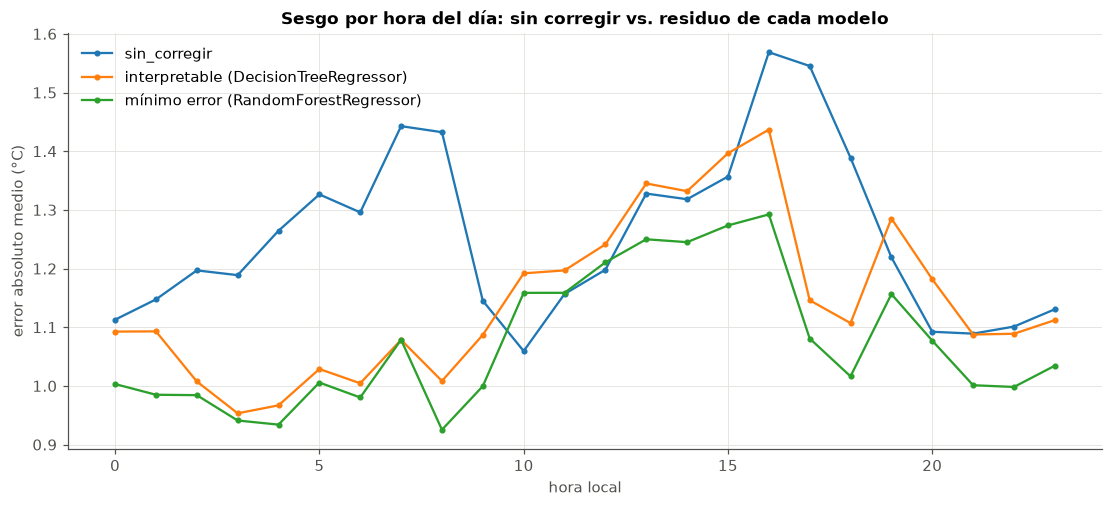

,sin_corregir,interpretable (DecisionTreeRegressor),mínimo error (RandomForestRegressor)
hora_local,,,
0,1.113,1.093,1.003
1,1.147,1.093,0.985
2,1.197,1.008,0.984
3,1.189,0.953,0.941
4,1.264,0.967,0.934
5,1.326,1.029,1.006
6,1.296,1.004,0.980
7,1.443,1.078,1.079
8,1.432,1.008,0.925


In [13]:
sesgo_hora = comparar_sesgo_por_corte(datos_test, 'hora_local', predicciones_test)

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
sesgo_hora.plot(ax=ax, marker='o', ms=3)
ax.set(xlabel='hora local', ylabel='error absoluto medio (°C)', title='Sesgo por hora del día: sin corregir vs. residuo de cada modelo')
ax.legend(frameon=False)
figuras['03_sesgo_por_hora_pre_post'] = fig
plt.show()
sesgo_hora.round(3)

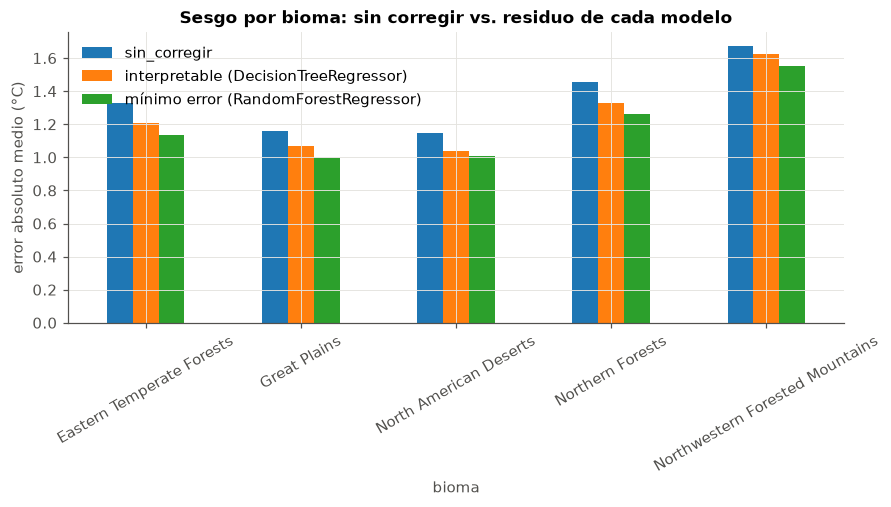

,sin_corregir,interpretable (DecisionTreeRegressor),mínimo error (RandomForestRegressor)
bioma,,,
Eastern Temperate Forests,1.327,1.205,1.137
Great Plains,1.161,1.069,0.997
North American Deserts,1.147,1.039,1.011
Northern Forests,1.453,1.326,1.264
Northwestern Forested Mountains,1.672,1.623,1.554


In [14]:
sesgo_bioma = comparar_sesgo_por_corte(datos_test, 'bioma', predicciones_test, min_n=20)

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
sesgo_bioma.plot(kind='bar', ax=ax)
ax.set(ylabel='error absoluto medio (°C)', title='Sesgo por bioma: sin corregir vs. residuo de cada modelo')
ax.tick_params(axis='x', rotation=30)
ax.legend(frameon=False)
figuras['04_sesgo_por_bioma_pre_post'] = fig
plt.show()
sesgo_bioma.round(3)

Si el modelo capturó el sesgo, la brecha entre categorías (horas del día, biomas) debería achicarse en el residuo
respecto a la serie sin corregir -una línea/barra más plana que la de "sin_corregir". Si una categoría sigue con
error alto en el residuo, el modelo no absorbió ese sesgo específico (candidato a investigar más, o a sumar una
feature que lo capture mejor).

### ¿Por qué empeora justo al mediodía (10h-14h local)?

`error_temp_c` tiene un ciclo diario fuerte -negativo durante la noche/madrugada (hasta -1,17 a las 8h), cruza por
cero alrededor de las 9-10h, y se vuelve positivo durante la tarde (hasta +1,25 a las 17h). `error_temp_c_lag6`
-la segunda feature más importante en ambos modelos, después de `lag24`- es el error de **6 horas antes**: para
predecir la hora 11h-13h, ese lag viene de la hora 5h-7h, que todavía está del lado *negativo* del ciclo, antes de
que ocurra el cruce por cero.

La correlación entre `error_temp_c_lag6` y el error real se calculó por hora local, y colapsa exactamente en esa
ventana (de ~0,3-0,47 el resto del día a 0,06-0,19 entre las 10h y las 14h) -la feature en la que más confían los
modelos deja de servir justo cuando el signo del error está cambiando. El resultado: ambos modelos siguen
prediciendo valores negativos un par de horas después de que el error real ya cruzó a positivo (a las 10h, por
ejemplo, Random Forest predice -1,03 cuando el error real promedio es -0,08) -van "atrasados" respecto al ciclo
diario, y esa predicción desfasada termina más lejos del valor real que directamente predecir 0.

`hora_sin`/`hora_cos` deberían ayudar a corregir esto, y de hecho son la 2ª y 3ª feature más importante -pero el
momento exacto del cruce por cero varía de estación en estación (depende de latitud, estación del año local,
nubosidad), así que una corrección horaria *global* (una sola curva para las 466 estaciones) no alcanza a ajustar
el desfasaje de `lag6` con la precisión que haría falta en esta ventana de transición.

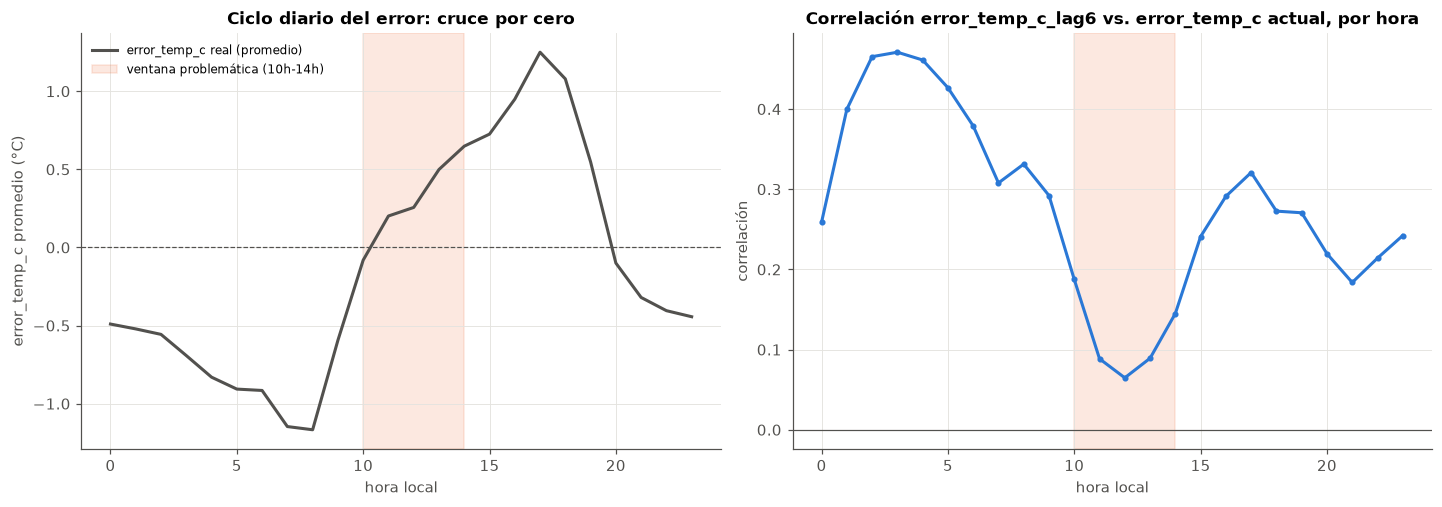

hora_local
0     0.259
1     0.400
2     0.465
3     0.471
4     0.461
5     0.427
6     0.379
7     0.308
8     0.331
9     0.292
10    0.187
11    0.089
12    0.065
13    0.089
14    0.145
15    0.241
16    0.291
17    0.321
18    0.273
19    0.271
20    0.220
21    0.184
22    0.214
23    0.242
dtype: float64

In [15]:
corr_lag6_por_hora = datos_test.groupby('hora_local').apply(
    lambda d: d['error_temp_c_lag6'].corr(d['error_temp_c']), include_groups=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

ax = axes[0]
perfil_hora = datos_test.groupby('hora_local')['error_temp_c'].mean()
ax.plot(perfil_hora.index, perfil_hora.values, color=GRIS_TEXTO, lw=2, label='error_temp_c real (promedio)')
ax.axhline(0, color=GRIS_TEXTO, lw=0.8, ls='--')
ax.axvspan(10, 14, color=NARANJA, alpha=0.15, label='ventana problemática (10h-14h)')
ax.set(xlabel='hora local', ylabel='error_temp_c promedio (°C)', title='Ciclo diario del error: cruce por cero')
ax.legend(frameon=False, fontsize=8)

ax2 = axes[1]
ax2.plot(corr_lag6_por_hora.index, corr_lag6_por_hora.values, color=AZUL, lw=2, marker='o', ms=3)
ax2.axhline(0, color=GRIS_TEXTO, lw=0.8)
ax2.axvspan(10, 14, color=NARANJA, alpha=0.15)
ax2.set(xlabel='hora local', ylabel='correlación', title='Correlación error_temp_c_lag6 vs. error_temp_c actual, por hora')

figuras['05_colapso_lag6_mediodia'] = fig
plt.show()
corr_lag6_por_hora.round(3)

### SHAP local: explicando una predicción puntual en la ventana problemática

El `TreeExplainer` de la sección 5 ya calcula Shapley values exactos para el Random Forest -no hace falta instalar
LIME ni aproximar nada nuevo: alcanza con pedirle la explicación de una sola fila en vez de la muestra de 500 que
usa el `summary_plot` global. Se elige el caso con mayor error absoluto del residuo dentro de la ventana 10h-13h
local (la franja problemática de la subsección anterior), para ver en concreto qué features empujaron al modelo a
una predicción tan alejada del error real en ese momento del ciclo diario.

In [16]:
ventana_problema = datos_test[datos_test['hora_local'].between(10, 13)].copy()
ventana_problema['prediccion_min_error'] = modelo_min_error_final.predict(X_test.loc[ventana_problema.index])
ventana_problema['residuo_abs'] = (ventana_problema['error_temp_c'] - ventana_problema['prediccion_min_error']).abs()

idx_caso = ventana_problema['residuo_abs'].idxmax()
caso = ventana_problema.loc[idx_caso]

print(f"Estación {caso['station_id']}, {caso['target_hour_utc']} UTC (hora local {caso['hora_local']}h)")
print(f"error_temp_c real: {caso['error_temp_c']:.3f} °C | predicción: {caso['prediccion_min_error']:.3f} °C | "
      f"residuo: {caso['residuo_abs']:.3f} °C")

Estación KELD, 2026-10-31 18:00:00+00:00 UTC (hora local 13h)
error_temp_c real: -6.100 °C | predicción: 0.589 °C | residuo: 6.689 °C


In [17]:
fila_transformada = X_test_transformado.loc[[idx_caso]]
shap_caso = explainer(fila_transformada)

contribuciones_caso = pd.Series(shap_caso.values[0], index=nombres_features_min_error,
                                 name='contribución SHAP (°C)').sort_values(key=np.abs, ascending=False)
print(f'base_value (predicción promedio del modelo): {shap_caso.base_values[0]:.3f} °C')
contribuciones_caso

base_value (predicción promedio del modelo): 0.084 °C


num__error_temp_c_lag24                       0.495217
num__fcst_pop_pct                             0.345818
num__hora_cos                                -0.113387
num__elevation                               -0.081974
num__hora_sin                                 0.073510
num__obs_windspeed_kmh_lag6                  -0.068626
num__obs_rh_pct_lag6                         -0.056578
num__fcst_temp_c                             -0.042718
num__error_temp_c_vecinas_lag6_mean          -0.034892
num__error_temp_c_roll3_mean                 -0.020737
num__area_urbana_km2                         -0.011792
num__obs_dewpoint_c_lag6                      0.011633
num__error_temp_c_lag6                        0.008517
num__obs_wind_direction_cos_lag6              0.008098
num__dist_area_urbana_km                     -0.008069
num__dist_aeropuerto_km                       0.002605
num__obs_wind_direction_sin_lag6             -0.001970
cat__bioma_Great Plains                       0.001936
num__en_ar

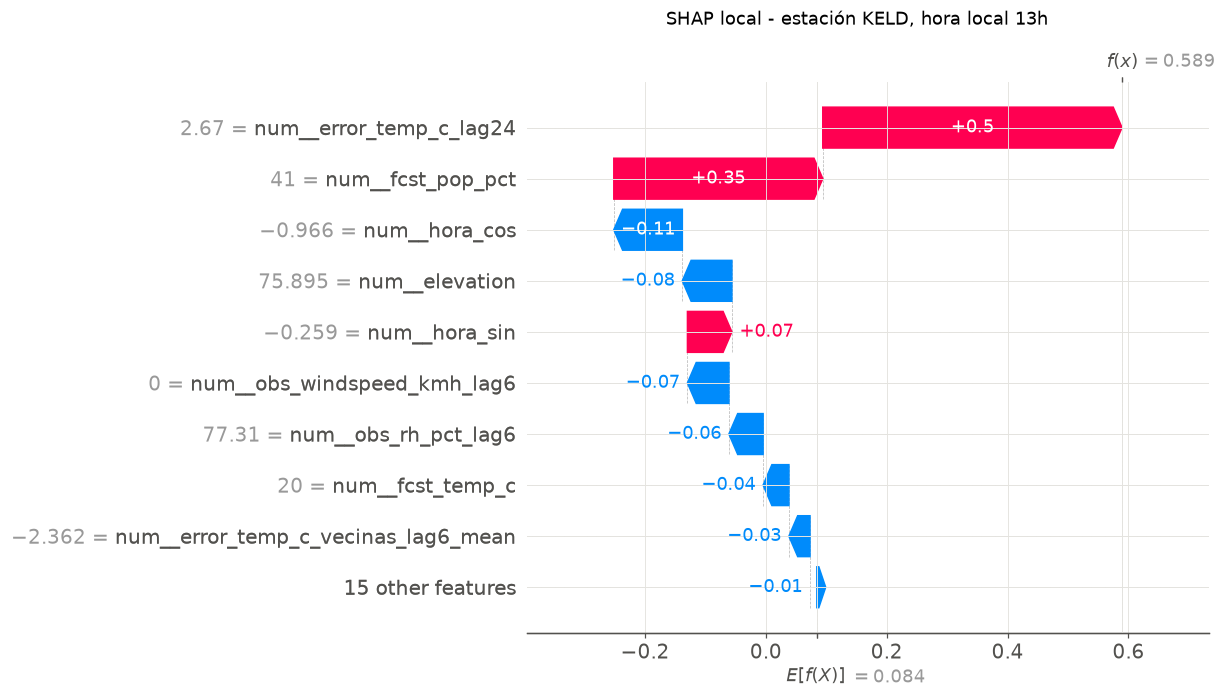

In [18]:
shap.plots.waterfall(shap_caso[0], show=False)
fig = plt.gcf()
fig.suptitle(f'SHAP local - estación {caso["station_id"]}, hora local {caso["hora_local"]}h')
figuras['07_shap_local_caso_mediodia'] = fig
plt.show()

El caso elegido (estación `KELD`, 31/10 18h UTC = 13h local) resultó ser un outlier extremo, no un ejemplo típico
del mecanismo de la subsección anterior: `error_temp_c` real fue -6,1 °C -muy por fuera del rango habitual (±1-1,5
°C)-, y el modelo predijo apenas +0,589 °C, casi sin moverse de su `base_value` (0,084 °C). Los dos drivers que lo
empujaron en esa dirección fueron `error_temp_c_lag24` (+0,495) y `fcst_pop_pct` (+0,346) -el pronóstico de
probabilidad de precipitación-, con `hora_cos` (-0,113) y `elevation` (-0,082) tirando un poco en contra.

El dato más revelador es que **`error_temp_c_lag6` -el feature señalado como "atrasado" en la subsección
anterior- casi no participa acá (+0,0085, la 13ª contribución de 24)**: esta falla no es el mecanismo del cruce
por cero del ciclo diario, es un mecanismo distinto. Ninguna de las features de historia reciente
(`lag6`/`lag24`/`roll3_mean`/`vecinas_lag6_mean`) venía mostrando señales de una desviación de esta magnitud, así
que el modelo se quedó cerca de su comportamiento "normal" para esa hora y erró por 6,7 °C. Es una limitación
distinta a nombrar en el informe junto con la del mediodía: el modelo captura bien el sesgo sistemático (ciclo
diario, bioma), pero no tiene ninguna feature que anticipe una anomalía puntual grande y repentina -tendría que
venir de afuera (p. ej. una condición sinóptica inusual) y hoy no está en el feature set.

## 8. Qué sigue

- Esta notebook ya usa los modelos reales de Etapa A (`7_modelado_global.ipynb`), así que las secciones 4-7 son la
  interpretabilidad real, no una prueba del scaffolding.
- Si se vuelve a correr `7_modelado_global.ipynb` (por ejemplo, agregando una feature nueva o ajustando un grid) y
  cambia qué modelo gana en cada categoría, esta notebook no necesita cambios de código -`nombre_interpretable`/
  `nombre_min_error` y las features se recalculan solos a partir de lo que se haya guardado.
- **Hallazgo pendiente de seguimiento**: el modelo empeora respecto de no corregir en la ventana 10h-14h local -la
  causa raíz (sección de arriba) es que `error_temp_c_lag6` pierde casi toda su correlación con el error justo en
  el cruce por cero del ciclo diario. Posibles mitigaciones a evaluar en una iteración futura: un lag más corto
  sólo para esa ventana, una feature que capture directamente "distancia al cruce por cero" en vez de depender de
  `hora_sin`/`hora_cos` global, o modelos por bioma/región en vez de uno global.
- Falta: redactar el informe (entregable 3) comparando ambos modelos -performance de la sección 3, insight de
  interpretabilidad de las secciones 4-7 (incluido este hallazgo del mediodía)- y el dashboard (entregable 4, Etapa
  C, todavía no empezado).

In [19]:
import os

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')

resultados.to_csv(OUT + 'tabla_resultados.csv', index=False)
importancia_interpretable.to_csv(OUT + 'tabla_feature_importance_interpretable.csv')
importancia_shap.to_csv(OUT + 'tabla_shap_min_error.csv')
comparacion_permutacion.to_csv(OUT + 'tabla_permutation_importance.csv')
contribuciones_caso.to_csv(OUT + 'tabla_shap_local_caso_mediodia.csv')
sesgo_hora.to_csv(OUT + 'tabla_sesgo_por_hora.csv')
sesgo_bioma.to_csv(OUT + 'tabla_sesgo_por_bioma.csv')
print(f'Guardados {len(figuras)} gráfico(s) y 7 tablas en {OUT}')

Guardados 7 gráfico(s) y 7 tablas en ../data/out/interpretabilidad/
